# 3. Logistic Regression for Shot xG

IT461 Practical Machine Learning | Group 10 | Member 3

In this notebook I train a Logistic Regression model that predicts whether a non-penalty shot ends in a goal (1) or not (0). The predicted probability of a goal is the shot's expected goals (xG) value.

I train the model twice, once for each feature set:
- Location-only: `distance` and `angle`
- Context-aware: distance and angle plus six features about how the shot was taken (body part, technique, first time, shot type, play pattern, under pressure)

Logistic Regression fits this problem well because it outputs a probability directly, and its coefficients tell us how much each feature raises or lowers the chance of scoring.

How to run: run all cells from top to bottom. The notebook uses the shared dataset, train/test split and preprocessing from the repository. In a new Colab session it clones the repository by itself, and if that fails it asks you to upload the repository as a ZIP.

## 3.1 Setup

The first cell finds the project folder so we can read the shared data and import `src/preprocessing.py`. If the notebook is opened in a fresh Colab session where the project does not exist yet, it downloads it from GitHub.

In [1]:
from pathlib import Path
import sys
import subprocess
import zipfile

REPO_URL = "https://github.com/Falhebshi/IT461-football-shot-probability.git"
DATA_FILE = "data/processed/modeling_dataset.csv"

# Look for the project folder first (current folder, then one level up).
project_root = Path.cwd()
if not (project_root / DATA_FILE).exists():
    if (project_root.parent / DATA_FILE).exists():
        project_root = project_root.parent
    else:
        # Not found, so we are probably in a new Colab session: clone the repo,
        # and if that fails ask for the ZIP instead.
        clone_dir = Path.cwd() / "IT461-football-shot-probability"
        if not clone_dir.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(clone_dir)])
        if (clone_dir / DATA_FILE).exists():
            project_root = clone_dir
        else:
            from google.colab import files
            print("Upload the IT461 project repository ZIP:")
            uploaded = files.upload()
            zip_name = next(name for name in uploaded if name.lower().endswith(".zip"))
            with zipfile.ZipFile(zip_name) as archive:
                archive.extractall(Path.cwd())
            project_root = next(
                path for path in Path.cwd().iterdir()
                if path.is_dir() and (path / DATA_FILE).exists()
            )

sys.path.insert(0, str(project_root))
print("Project folder:", project_root)

Project folder: /content/IT461-football-shot-probability


In [2]:
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, log_loss, brier_score_loss,
    average_precision_score, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, classification_report,
)

from src.preprocessing import (
    LOCATION_FEATURES, CONTEXT_FEATURES,
    make_location_preprocessor, make_context_preprocessor,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*penalty is deprecated.*")  # warning only shows in newer sklearn
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)
print("Libraries and shared preprocessing loaded.")

Python: 3.13.18 | scikit-learn: 1.6.1
Libraries and shared preprocessing loaded.


## 3.2 Loading the data

`modeling_dataset.csv` has the engineered features but they are not scaled or encoded yet. That is on purpose: the scaler and encoder have to learn from the training data only, otherwise information from the test set leaks into the model.

`model_split.csv` says which shots are in train and which are in test. I join the two files on the shot ID and match ID (not on row order) and then check that no match ends up in both sets.

In [3]:
data = pd.read_csv(project_root / "data/processed/modeling_dataset.csv")
splits = pd.read_csv(project_root / "data/processed/model_split.csv")

# Join on the IDs so we never rely on the row order of the two files.
assert data["id"].is_unique and splits["id"].is_unique
shots = data.merge(splits, on=["id", "match_id"], validate="one_to_one")
assert len(shots) == len(data) == len(splits)
assert set(shots["split"]) == {"train", "test"}
assert set(shots["goal"].unique()) == {0, 1}
assert shots[CONTEXT_FEATURES].notna().all().all()

train = shots[shots["split"] == "train"].reset_index(drop=True)
test = shots[shots["split"] == "test"].reset_index(drop=True)

# A match should be either in train or in test, never both.
assert set(train["match_id"]).isdisjoint(set(test["match_id"]))
print("Total shots:", len(shots), "| Total matches:", shots["match_id"].nunique())
print("Training:", len(train), "shots |", train["match_id"].nunique(), "matches")
print("Testing: ", len(test), "shots |", test["match_id"].nunique(), "matches")
print("Match overlap: 0")

Total shots: 12374 | Total matches: 500
Training: 9900 shots | 400 matches
Testing:  2474 shots | 100 matches
Match overlap: 0


In [4]:
# Goal rate in train and test should be about the same (~11%).
class_counts = shots.groupby("split")["goal"].agg(
    shots="count", goals="sum", goal_rate="mean"
)
class_counts["non_goals"] = class_counts["shots"] - class_counts["goals"]
display(class_counts[["shots", "non_goals", "goals", "goal_rate"]].round(4))

,shots,non_goals,goals,goal_rate
split,,,,
test,2474,2197,277,0.1120
train,9900,8794,1106,0.1117


## 3.3 Feature sets and CV folds

Logistic Regression multiplies each feature by a weight, adds them up, and passes the result through the sigmoid function so the output is always between 0 and 1:

$$P(\text{goal}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k)}}$$

Scaling the numeric features matters here because regularization penalizes all coefficients in the same way, so the features need to be on a similar scale. The preprocessing sits inside the pipeline, which means it gets refitted on every training fold.

For cross-validation I use 3-fold `StratifiedGroupKFold` grouped by `match_id`, with the same random seed as the SVM notebook. This way both models are tuned on exactly the same folds, and shots from the same match never end up split between training and validation.

In [5]:
y_train = train["goal"]
y_test = test["goal"]

X_train_location = train[LOCATION_FEATURES]
X_test_location = test[LOCATION_FEATURES]
X_train_context = train[CONTEXT_FEATURES]
X_test_context = test[CONTEXT_FEATURES]

# Same splitter and seed as the SVM notebook, so both use identical folds.
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
cv_folds = list(cv.split(X_train_location, y_train, groups=train["match_id"]))

for number, (train_idx, val_idx) in enumerate(cv_folds, 1):
    train_matches = set(train.loc[train_idx, "match_id"])
    val_matches = set(train.loc[val_idx, "match_id"])
    assert train_matches.isdisjoint(val_matches)
    print(f"Fold {number}: {len(train_idx)} training shots, {len(val_idx)} validation shots")

Fold 1: 6639 training shots, 3261 validation shots
Fold 2: 6562 training shots, 3338 validation shots
Fold 3: 6599 training shots, 3301 validation shots


## 3.4 Tuning the model

I tune three settings:

- `C` controls how strong the regularization is (it is the inverse, so smaller C means stronger). A very small C pushes the coefficients towards zero and the model becomes too simple. A very large C lets them grow freely, which can overfit, especially on categories with only a few shots. I try values from 0.001 to 100.
- `penalty` is the type of regularization. L2 shrinks all coefficients a bit, while L1 can set some of them to exactly zero, so it also works as a kind of feature selection. I use the `liblinear` solver because it supports both.
- `class_weight` is either None or balanced. Only about 11% of shots are goals, so like the SVM notebook I check whether giving goals more weight helps.

That gives 6 x 2 x 2 = 24 combinations for each feature set.

To pick the best combination I use the mean validation log loss. The output of this project is a probability, and log loss checks whether the probabilities themselves are right, not only whether goals get higher scores than non-goals. I still record ROC AUC so the results can be compared with the SVM. The test set is not touched during tuning.

In [6]:
parameter_grid = {
    "logreg__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "logreg__penalty": ["l2", "l1"],
    "logreg__class_weight": [None, "balanced"],
}
# sklearn maximizes scores, so log loss is used as a negative number
scoring = {"log_loss": "neg_log_loss", "roc_auc": "roc_auc"}

print("Grid candidates per feature set:",
      len(parameter_grid["logreg__C"]) * len(parameter_grid["logreg__penalty"])
      * len(parameter_grid["logreg__class_weight"]),
      "(each tested across 3 folds)")

Grid candidates per feature set: 24 (each tested across 3 folds)


In [7]:
def cv_table(search):
    """Turn GridSearchCV results into a smaller table, best log loss first."""
    results = pd.DataFrame(search.cv_results_)
    table = pd.DataFrame({
        "C": results["param_logreg__C"],
        "Penalty": results["param_logreg__penalty"],
        "Class weight": results["param_logreg__class_weight"].fillna("None"),
        "Mean CV log loss": -results["mean_test_log_loss"],
        "Log loss std. dev.": results["std_test_log_loss"],
        "Mean CV ROC AUC": results["mean_test_roc_auc"],
        "AUC std. dev.": results["std_test_roc_auc"],
    })
    return table.sort_values("Mean CV log loss").reset_index(drop=True)

### 3.4.1 Location-only model

Grid search over the 24 combinations using only `distance` and `angle`.

In [8]:
location_pipeline = Pipeline([
    ("preprocessing", make_location_preprocessor()),
    ("logreg", LogisticRegression(solver="liblinear", max_iter=5000)),
])

location_search = GridSearchCV(
    location_pipeline, parameter_grid, scoring=scoring,
    refit="log_loss", cv=cv_folds, n_jobs=1  # refit the best setting on all training data
)
start = time.perf_counter()
location_search.fit(X_train_location, y_train)
location_seconds = time.perf_counter() - start

print("Location-only best parameters:", location_search.best_params_)
print("Location-only best CV log loss:", round(-location_search.best_score_, 4))
print(f"Grid search time: {location_seconds:.1f} seconds")

Location-only best parameters: {'logreg__C': 10, 'logreg__class_weight': None, 'logreg__penalty': 'l2'}
Location-only best CV log loss: 0.3134
Grid search time: 5.2 seconds


In [9]:
display(cv_table(location_search).round(4))

,C,Penalty,Class weight,Mean CV log loss,Log loss std. dev.,Mean CV ROC AUC,AUC std. dev.
0,10.000,l2,None,0.3134,0.0042,0.7353,0.0046
1,100.000,l2,None,0.3134,0.0042,0.7353,0.0046
2,100.000,l1,None,0.3134,0.0042,0.7353,0.0046
3,10.000,l1,None,0.3134,0.0042,0.7353,0.0046
4,1.000,l2,None,0.3134,0.0041,0.7353,0.0046
5,1.000,l1,None,0.3134,0.0042,0.7353,0.0046
6,0.100,l1,None,0.3134,0.0041,0.7353,0.0046
7,0.100,l2,None,0.3135,0.0041,0.7353,0.0046
8,0.010,l1,None,0.3174,0.0040,0.7351,0.0043
9,0.010,l2,None,0.3192,0.0036,0.7355,0.0046


### 3.4.2 Context-aware model

Same grid and same folds, this time with all eight features.

In [10]:
context_pipeline = Pipeline([
    ("preprocessing", make_context_preprocessor()),
    ("logreg", LogisticRegression(solver="liblinear", max_iter=5000)),
])

context_search = GridSearchCV(
    context_pipeline, parameter_grid, scoring=scoring,
    refit="log_loss", cv=cv_folds, n_jobs=1
)
start = time.perf_counter()
context_search.fit(X_train_context, y_train)
context_seconds = time.perf_counter() - start

print("Context-aware best parameters:", context_search.best_params_)
print("Context-aware best CV log loss:", round(-context_search.best_score_, 4))
print(f"Grid search time: {context_seconds:.1f} seconds")

Context-aware best parameters: {'logreg__C': 10, 'logreg__class_weight': None, 'logreg__penalty': 'l2'}
Context-aware best CV log loss: 0.2986
Grid search time: 23.7 seconds


In [11]:
display(cv_table(context_search).round(4))

,C,Penalty,Class weight,Mean CV log loss,Log loss std. dev.,Mean CV ROC AUC,AUC std. dev.
0,10.000,l2,None,0.2986,0.0025,0.7722,0.0029
1,10.000,l1,None,0.2987,0.0025,0.7723,0.0028
2,100.000,l2,None,0.2988,0.0026,0.7722,0.0028
3,1.000,l2,None,0.2989,0.0020,0.7710,0.0028
4,100.000,l1,None,0.2989,0.0026,0.7722,0.0028
5,1.000,l1,None,0.2991,0.0018,0.7706,0.0033
6,0.100,l2,None,0.2999,0.0016,0.7690,0.0030
7,0.100,l1,None,0.3012,0.0015,0.7670,0.0032
8,0.010,l2,None,0.3069,0.0029,0.7566,0.0014
9,0.010,l1,None,0.3174,0.0040,0.7351,0.0043


### 3.4.3 How C affects the results

Validation scores for each value of C (class_weight = None). A very small C hurts both models. After C = 1 the curves are almost flat, so making the model less regularized does not help much beyond that point.

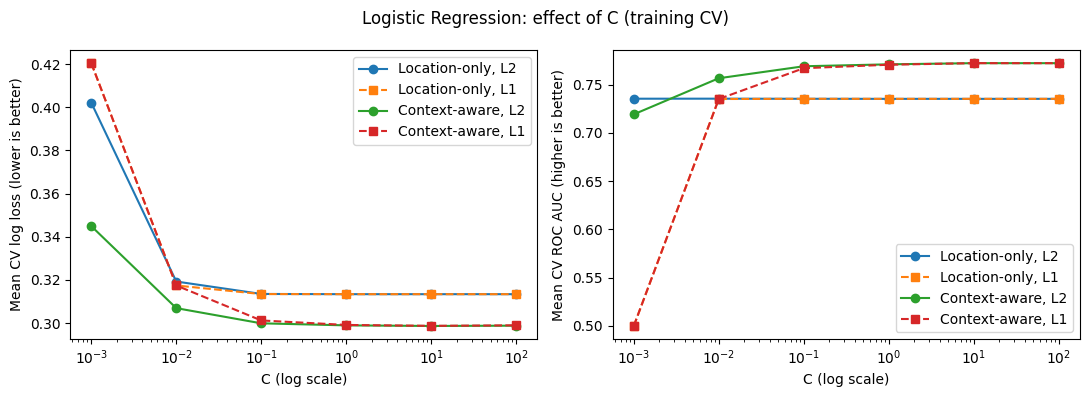

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, search in [("Location-only", location_search), ("Context-aware", context_search)]:
    table = cv_table(search)
    for penalty, style in [("l2", "-o"), ("l1", "--s")]:
        sub = table[(table["Class weight"] == "None") & (table["Penalty"] == penalty)].sort_values("C")
        label = f"{name}, {penalty.upper()}"
        axes[0].plot(sub["C"], sub["Mean CV log loss"], style, label=label)
        axes[1].plot(sub["C"], sub["Mean CV ROC AUC"], style, label=label)

for ax, ylabel in zip(axes, ["Mean CV log loss (lower is better)",
                             "Mean CV ROC AUC (higher is better)"]):
    ax.set_xscale("log")
    ax.set_xlabel("C (log scale)")
    ax.set_ylabel(ylabel)
    ax.legend()
fig.suptitle("Logistic Regression: effect of C (training CV)")
plt.tight_layout()
plt.show()

### 3.4.4 Balanced vs regular class weights

With balanced weights the ROC AUC stays almost the same, so the model still ranks the shots in the same order. But the log loss roughly doubles. Balanced weights make the model behave as if goals and misses were equally common, so every predicted probability goes up and no longer matches how often shots actually go in.

This is the opposite of what happened in the SVM notebook, where balancing was needed to get a reasonable model at all. Since Logistic Regression already gives probabilities, the regular weights are the better choice for xG.

In [13]:
weight_rows = []
for name, search in [("Location-only", location_search), ("Context-aware", context_search)]:
    table = cv_table(search)
    for weight in ["None", "balanced"]:
        selected = table[table["Class weight"] == weight]
        weight_rows.append({
            "Feature set": name,
            "Class weight": weight,
            "Best mean CV log loss": selected["Mean CV log loss"].min(),
            "Best mean CV ROC AUC": selected["Mean CV ROC AUC"].max(),
        })

display(pd.DataFrame(weight_rows).round(4))

,Feature set,Class weight,Best mean CV log loss,Best mean CV ROC AUC
0,Location-only,None,0.3134,0.7355
1,Location-only,balanced,0.6049,0.7355
2,Context-aware,None,0.2986,0.7723
3,Context-aware,balanced,0.5679,0.7717


### 3.4.5 L1 vs L2

Best L1 and best L2 result for each feature set (class_weight = None). I also refit the best L1 context model to see which features it drops. If L1 and L2 score about the same and L1 only removes a few weak features, it means the feature set is reasonable and nothing important needs to be removed.

In [14]:
penalty_rows = []
for name, search in [("Location-only", location_search), ("Context-aware", context_search)]:
    table = cv_table(search)
    table = table[table["Class weight"] == "None"]
    for penalty in ["l2", "l1"]:
        sub = table[table["Penalty"] == penalty]
        best = sub.loc[sub["Mean CV log loss"].idxmin()]
        penalty_rows.append({
            "Feature set": name, "Penalty": penalty.upper(), "Best C": best["C"],
            "Best mean CV log loss": best["Mean CV log loss"],
            "Mean CV ROC AUC": best["Mean CV ROC AUC"],
        })
penalty_table = pd.DataFrame(penalty_rows)
display(penalty_table.round(4))

# Refit the best L1 context model and check which coefficients became zero.
best_l1_C = penalty_table.query("`Feature set` == 'Context-aware' and Penalty == 'L1'")["Best C"].iloc[0]
l1_model = Pipeline([
    ("preprocessing", make_context_preprocessor()),
    ("logreg", LogisticRegression(solver="liblinear", penalty="l1", C=best_l1_C, max_iter=5000)),
]).fit(X_train_context, y_train)
names = [n.split("__", 1)[1] for n in l1_model.named_steps["preprocessing"].get_feature_names_out()]
l1_coefs = pd.Series(l1_model.named_steps["logreg"].coef_[0], index=names)
print(f"L1 (C={best_l1_C}) kept {(l1_coefs != 0).sum()} of {len(l1_coefs)} features.")
print("Features set to zero:", list(l1_coefs[l1_coefs == 0].index) or "none")

,Feature set,Penalty,Best C,Best mean CV log loss,Mean CV ROC AUC
0,Location-only,L2,10.0,0.3134,0.7353
1,Location-only,L1,100.0,0.3134,0.7353
2,Context-aware,L2,10.0,0.2986,0.7722
3,Context-aware,L1,10.0,0.2987,0.7723


L1 (C=10.0) kept 24 of 28 features.
Features set to zero: ['shot_technique_Normal', 'shot_type_Kick Off', 'play_pattern_Other', 'play_pattern_Regular Play']


## 3.5 Training the final models

The grid search only told us which settings work best. Here I take those settings and train each final model on the whole training set (all 9,900 shots), so every shot in the training data is used.

In [15]:
def build_model(make_preprocessor, best_params):
    """Logistic Regression pipeline with the settings chosen in tuning."""
    return Pipeline([
        ("preprocessing", make_preprocessor()),
        ("logreg", LogisticRegression(
            solver="liblinear",
            C=best_params["logreg__C"],
            penalty=best_params["logreg__penalty"],
            class_weight=best_params["logreg__class_weight"],
            max_iter=5000,
        )),
    ])

location_model = build_model(make_location_preprocessor, location_search.best_params_)
context_model = build_model(make_context_preprocessor, context_search.best_params_)

# Train both models on the full training set.
location_model.fit(X_train_location, y_train)
context_model.fit(X_train_context, y_train)

for name, model in [("Location-only", location_model), ("Context-aware", context_model)]:
    logreg = model.named_steps["logreg"]
    print(f"{name}: C={logreg.C}, penalty={logreg.penalty}, "
          f"class_weight={logreg.class_weight}, "
          f"trained on {len(y_train)} shots, {logreg.coef_.shape[1]} input features")

Location-only: C=10, penalty=l2, class_weight=None, trained on 9900 shots, 2 input features
Context-aware: C=10, penalty=l2, class_weight=None, trained on 9900 shots, 28 input features


In [16]:
# Quick check: these should match the models GridSearchCV refitted internally.
assert np.allclose(location_model.predict_proba(X_train_location),
                   location_search.best_estimator_.predict_proba(X_train_location))
assert np.allclose(context_model.predict_proba(X_train_context),
                   context_search.best_estimator_.predict_proba(X_train_context))
print("Final models match the best models from the grid search.")

Final models match the best models from the grid search.


## 3.6 Predicting xG on the test set

Now the test set is used for the first time. Unlike the SVM, Logistic Regression gives probabilities directly, so no calibration step is needed. The second column of `predict_proba` is the probability of a goal, which is the xG.

In [17]:
# location_model and context_model were trained in section 3.5

# column 1 = probability of a goal
location_xg = location_model.predict_proba(X_test_location)[:, 1]
context_xg = context_model.predict_proba(X_test_context)[:, 1]

example_predictions = test[["id", "goal"]].head(5).copy()
example_predictions["Location xG"] = location_xg[:5]
example_predictions["Context xG"] = context_xg[:5]
display(example_predictions.round(4))

,id,goal,Location xG,Context xG
0,c5341577-e1ca-4742-98fb-dc745cbbe103,0,0.0873,0.1277
1,1aedaf9e-bc12-4d0a-953d-bd0f7db3688a,0,0.0734,0.0875
2,96b28bfc-d174-4b38-86cf-5a43cda4a14f,0,0.0974,0.1065
3,b9ca5464-1f5a-401b-a31d-8101bd61072a,0,0.0638,0.0858
4,75bdc651-c041-4021-b201-cb9eb8b97837,1,0.7219,0.9305


### 3.6.1 Sanity check on the predictions

A useful xG model should give clearly different values to easy and hard chances, not just predict something close to 11% for every shot. The average predicted xG should also be close to the real goal rate.

In [18]:
probability_summary = pd.DataFrame({
    "Feature set": ["Location-only", "Context-aware"],
    "Mean xG": [location_xg.mean(), context_xg.mean()],
    "Std. dev.": [location_xg.std(), context_xg.std()],
    "Min xG": [location_xg.min(), context_xg.min()],
    "Median xG": [np.median(location_xg), np.median(context_xg)],
    "Max xG": [location_xg.max(), context_xg.max()],
})
display(probability_summary.round(4))
print(f"Actual test goal rate: {y_test.mean():.4f}")

,Feature set,Mean xG,Std. dev.,Min xG,Median xG,Max xG
0,Location-only,0.1117,0.0976,0.0017,0.0807,0.9147
1,Context-aware,0.1129,0.1205,0.0002,0.0772,0.9731


Actual test goal rate: 0.1120


## 3.7 What the model learned

One advantage of Logistic Regression is that we can read the coefficients:

- A positive coefficient means the feature makes a goal more likely, a negative one makes it less likely.
- The odds ratio is e^coefficient. An odds ratio of 2 means the odds of scoring double, and 0.5 means they are cut in half.

Distance and angle are standardized, so their coefficients are per one standard deviation. For the one-hot categories, each coefficient should be compared with the other categories in the same group.

In [19]:
def coefficient_table(model):
    names = model.named_steps["preprocessing"].get_feature_names_out()
    names = [name.split("__", 1)[1] for name in names]  # drop the "num__"/"cat__" prefix
    coefficients = model.named_steps["logreg"].coef_[0]
    table = pd.DataFrame({
        "Feature": names,
        "Coefficient": coefficients,
        "Odds ratio": np.exp(coefficients),
    })
    return table.sort_values("Coefficient", key=abs, ascending=False).reset_index(drop=True)

print("Location-only model")
display(coefficient_table(location_model).round(3))
print("Intercept:", round(location_model.named_steps["logreg"].intercept_[0], 3))

Location-only model


,Feature,Coefficient,Odds ratio
0,distance,-0.517,0.596
1,angle,0.388,1.474


Intercept: -2.343


,Feature,Coefficient,Odds ratio
0,shot_type_Corner,3.429,30.833
1,shot_type_Open Play,-2.056,0.128
2,shot_technique_Lob,1.836,6.271
3,shot_type_Free Kick,-1.754,0.173
4,shot_technique_Backheel,-1.575,0.207
5,distance,-0.836,0.433
6,shot_body_part_Head,-0.828,0.437
7,shot_technique_Overhead Kick,-0.706,0.494
8,play_pattern_From Corner,-0.603,0.547
9,angle,0.518,1.678


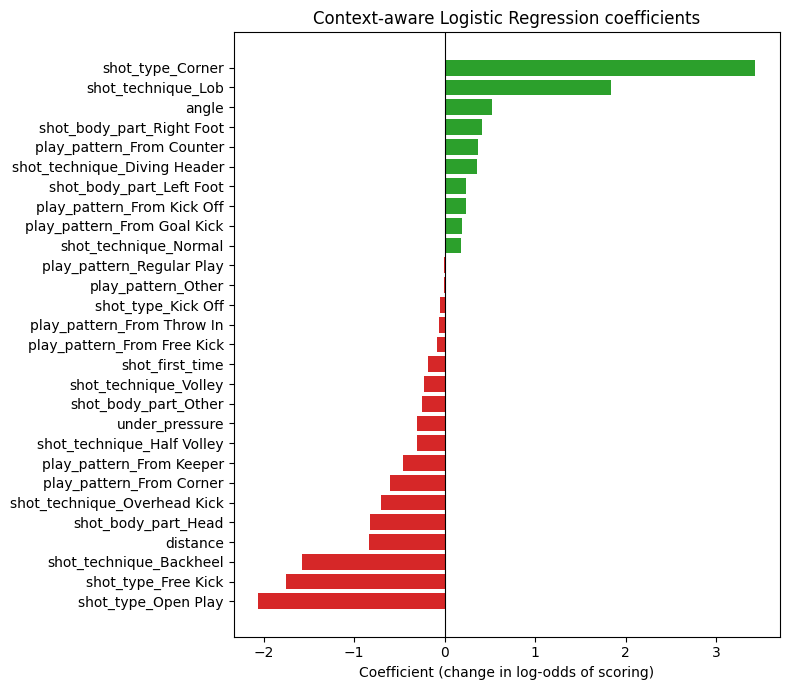

In [20]:
context_coefficients = coefficient_table(context_model)
display(context_coefficients.round(3))

plot_data = context_coefficients.sort_values("Coefficient")
colors = ["tab:red" if value < 0 else "tab:green" for value in plot_data["Coefficient"]]
plt.figure(figsize=(8, 7))
plt.barh(plot_data["Feature"], plot_data["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (change in log-odds of scoring)")
plt.title("Context-aware Logistic Regression coefficients")
plt.tight_layout()
plt.show()

### 3.7.1 A note on rare categories

Some categories appear in only a few shots in the training data. Their coefficients are based on very little evidence and can look large just by chance, so they should not be read as real effects. For example, `shot_type_Corner` has one of the biggest coefficients but only 3 training shots.

In [21]:
category_counts = []
for feature in ["shot_body_part", "shot_technique", "shot_type", "play_pattern"]:
    counts = train.groupby(feature)["goal"].agg(shots="count", goals="sum")
    for category, row in counts.iterrows():
        category_counts.append({
            "Feature": f"{feature}_{category}",
            "Training shots": row["shots"],
            "Training goals": row["goals"],
        })

category_counts = pd.DataFrame(category_counts)
rare = category_counts.merge(context_coefficients, on="Feature")
rare = rare[rare["Training shots"] < 100].sort_values("Training shots")
print("Categories with fewer than 100 training shots:")
display(rare.round(3))

Categories with fewer than 100 training shots:


,Feature,Training shots,Training goals,Coefficient,Odds ratio
13,shot_type_Kick Off,1,0,-0.051,0.950
11,shot_type_Corner,3,2,3.429,30.833
22,play_pattern_Other,18,4,-0.012,0.988
4,shot_technique_Backheel,34,3,-1.575,0.207
5,shot_technique_Diving Header,35,7,0.357,1.430
2,shot_body_part_Other,40,14,-0.252,0.777
9,shot_technique_Overhead Kick,49,5,-0.706,0.494


## 3.8 Evaluation on the test set

Almost 89% of shots are not goals, so a model that always says "no goal" already gets 89% accuracy. That is why accuracy is not enough here. I report:

- Precision, recall and F1 for the yes/no predictions
- ROC AUC and average precision for how well goals are ranked above non-goals
- Log loss and Brier score for how accurate the probabilities are

The baseline gives every shot the same xG (the training goal rate). To match the SVM notebook, the yes/no metrics use a threshold of 0.5. Recall at 0.5 is low because the model is rarely more than 50% sure about a goal, which is normal for shots. Section 3.8.6 looks at a better threshold.

In [22]:
# Baseline: same xG for every shot, equal to the training goal rate.
training_goal_rate = y_train.mean()
baseline_xg = np.full(len(test), training_goal_rate)

def evaluate_probabilities(name, probabilities, threshold=0.5):
    labels = (probabilities >= threshold).astype(int)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, labels),
        "Precision": precision_score(y_test, labels, zero_division=0),
        "Recall": recall_score(y_test, labels, zero_division=0),
        "F1": f1_score(y_test, labels, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "Average precision": average_precision_score(y_test, probabilities),
        "Log loss": log_loss(y_test, probabilities),
        "Brier score": brier_score_loss(y_test, probabilities),
    }

metrics = pd.DataFrame([
    evaluate_probabilities("Training-rate baseline", baseline_xg),
    evaluate_probabilities("Location-only LR", location_xg),
    evaluate_probabilities("Context-aware LR", context_xg),
])
pd.set_option("display.width", 200)
display(metrics.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC AUC,Average precision,Log loss,Brier score
0,Training-rate baseline,0.8880,0.0000,0.0000,0.0000,0.5000,0.1120,0.3506,0.0994
1,Location-only LR,0.8929,0.7308,0.0686,0.1254,0.7537,0.3367,0.3058,0.0881
2,Context-aware LR,0.8985,0.7500,0.1408,0.2371,0.7968,0.4306,0.2839,0.0813


### 3.8.1 ROC curve

How well each model separates goals from non-goals across all thresholds. The closer the curve is to the top-left corner, the better.

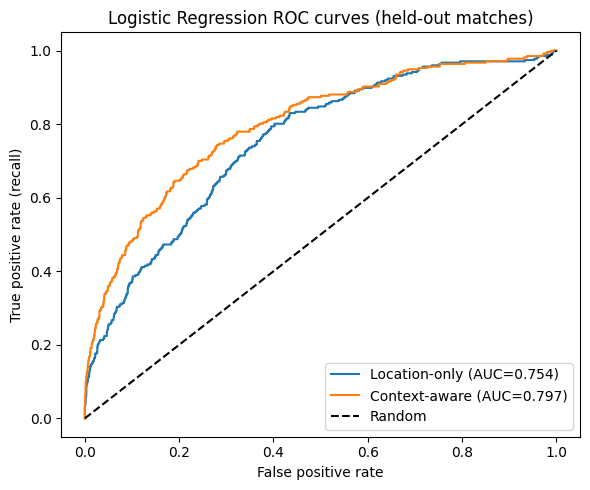

In [23]:
plt.figure(figsize=(6, 5))
for label, probabilities in [("Location-only", location_xg),
                             ("Context-aware", context_xg)]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{label} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("Logistic Regression ROC curves (held-out matches)")
plt.legend()
plt.tight_layout()
plt.show()

### 3.8.2 Precision-recall curve

Since goals are rare, the precision-recall curve is more informative than ROC on its own. The dashed line is what a random model would get (the test goal rate).

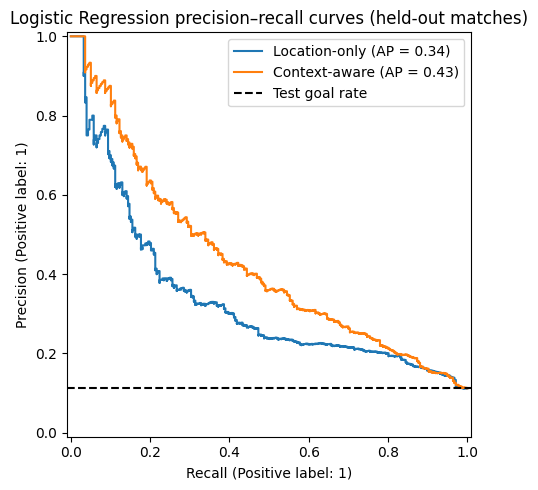

In [24]:
fig, ax = plt.subplots(figsize=(6, 5))
for label, probabilities in [("Location-only", location_xg),
                             ("Context-aware", context_xg)]:
    PrecisionRecallDisplay.from_predictions(y_test, probabilities, name=label, ax=ax)
ax.axhline(y_test.mean(), color="black", linestyle="--", label="Test goal rate")
ax.set_title("Logistic Regression precision–recall curves (held-out matches)")
ax.legend()
plt.tight_layout()
plt.show()

### 3.8.3 Calibration

This compares the predicted xG with how often those shots actually went in. If shots with xG around 0.20 score about 20% of the time, the model is well calibrated there. Points on the diagonal mean perfect calibration. Logistic Regression is trained by minimizing log loss, so it is usually well calibrated without extra steps.

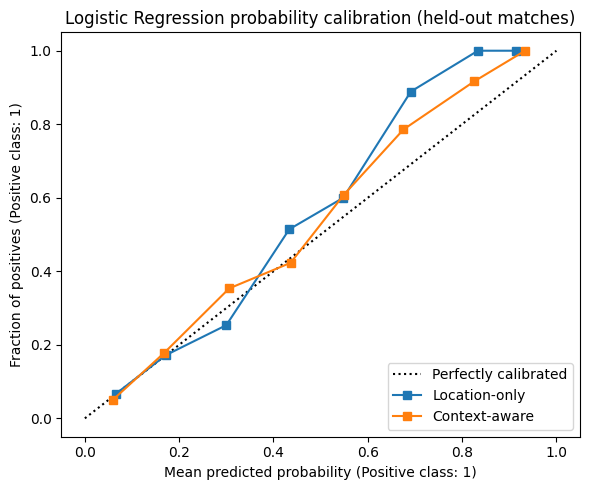

In [25]:
fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_test, location_xg, n_bins=8,
                                    name="Location-only", ax=ax)
CalibrationDisplay.from_predictions(y_test, context_xg, n_bins=8,
                                    name="Context-aware", ax=ax)
ax.set_title("Logistic Regression probability calibration (held-out matches)")
plt.tight_layout()
plt.show()

### 3.8.4 Confusion matrix (threshold 0.5)

Correct and wrong predictions for the context-aware model when a shot is labelled a goal only if xG >= 0.5.

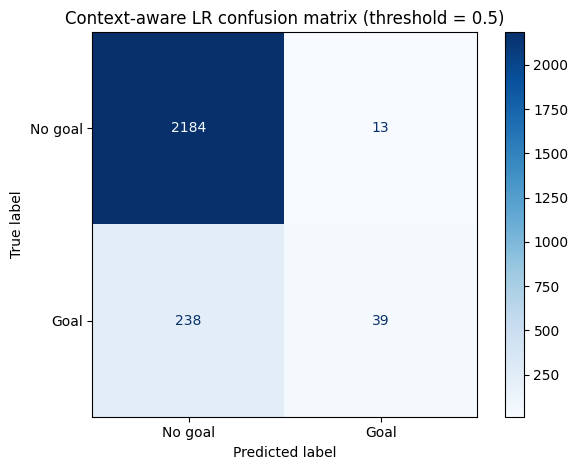

In [26]:
context_labels = (context_xg >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(
    y_test, context_labels, display_labels=["No goal", "Goal"], cmap="Blues"
)
plt.title("Context-aware LR confusion matrix (threshold = 0.5)")
plt.tight_layout()
plt.show()

### 3.8.5 Results per class

Precision, recall and F1 for goals and non-goals separately, at threshold 0.5.

In [27]:
for name, probabilities in [("Location-only", location_xg),
                            ("Context-aware", context_xg)]:
    print(f"\n{name} LR (threshold = 0.5)")
    labels = (probabilities >= 0.5).astype(int)
    print(classification_report(y_test, labels,
          target_names=["No goal", "Goal"], digits=3, zero_division=0))


Location-only LR (threshold = 0.5)
              precision    recall  f1-score   support

     No goal      0.895     0.997     0.943      2197
        Goal      0.731     0.069     0.125       277

    accuracy                          0.893      2474
   macro avg      0.813     0.533     0.534      2474
weighted avg      0.876     0.893     0.851      2474


Context-aware LR (threshold = 0.5)
              precision    recall  f1-score   support

     No goal      0.902     0.994     0.946      2197
        Goal      0.750     0.141     0.237       277

    accuracy                          0.899      2474
   macro avg      0.826     0.567     0.591      2474
weighted avg      0.885     0.899     0.866      2474



### 3.8.6 Picking a better threshold

A threshold of 0.5 only labels a shot as a goal when the model is more than 50% sure, and that rarely happens. If we want yes/no predictions, a lower threshold gives a better balance between precision and recall.

I choose the threshold on the training data, not the test set. Each training shot gets an out-of-fold prediction from a model that did not see its match, and I pick the threshold with the best F1 on those predictions. Then I apply it to the test set. This only changes how probabilities are turned into labels; the xG values stay the same.

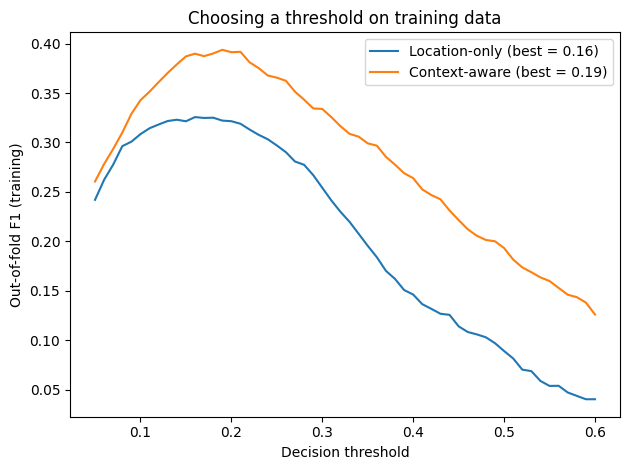

,Model,Threshold (from training CV),Test precision,Test recall,Test F1
0,Location-only LR,0.16,0.2679,0.4585,0.3382
1,Context-aware LR,0.19,0.3866,0.4801,0.4283


In [28]:
thresholds = np.arange(0.05, 0.61, 0.01)
threshold_rows = []
chosen_thresholds = {}

for name, model, X_train_set, X_test_set, probabilities in [
    ("Location-only", location_model, X_train_location, X_test_location, location_xg),
    ("Context-aware", context_model, X_train_context, X_test_context, context_xg),
]:
    # out-of-fold predictions on the training set
    oof = cross_val_predict(model, X_train_set, y_train, cv=cv_folds,
                            method="predict_proba")[:, 1]
    f1_scores = [f1_score(y_train, oof >= t) for t in thresholds]
    best_t = float(thresholds[int(np.argmax(f1_scores))])
    chosen_thresholds[name] = best_t
    plt.plot(thresholds, f1_scores, label=f"{name} (best = {best_t:.2f})")

    labels = (probabilities >= best_t).astype(int)
    threshold_rows.append({
        "Model": f"{name} LR",
        "Threshold (from training CV)": best_t,
        "Test precision": precision_score(y_test, labels, zero_division=0),
        "Test recall": recall_score(y_test, labels),
        "Test F1": f1_score(y_test, labels),
    })

plt.xlabel("Decision threshold")
plt.ylabel("Out-of-fold F1 (training)")
plt.title("Choosing a threshold on training data")
plt.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame(threshold_rows).round(4))

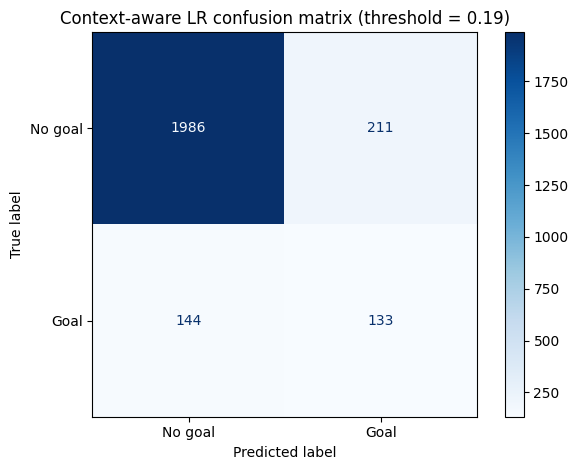

In [29]:
best_t = chosen_thresholds["Context-aware"]
ConfusionMatrixDisplay.from_predictions(
    y_test, (context_xg >= best_t).astype(int),
    display_labels=["No goal", "Goal"], cmap="Blues"
)
plt.title(f"Context-aware LR confusion matrix (threshold = {best_t:.2f})")
plt.tight_layout()
plt.show()

## 3.9 Best model and findings

The best model is chosen by cross-validation log loss, the same criterion used in tuning, and not by test results. After that I compare the two feature sets and the baseline on the test set.

In [30]:
# Choose the best model by CV log loss (best_score_ is negative log loss).
if location_search.best_score_ >= context_search.best_score_:
    best_name, best_search = "Location-only", location_search
else:
    best_name, best_search = "Context-aware", context_search

print(f"Best LR by cross-validation log loss: {best_name}")
print("Best settings:", best_search.best_params_)
print(f"Mean CV log loss: {-best_search.best_score_:.4f}")

location_row = metrics.loc[metrics["Model"] == "Location-only LR"].iloc[0]
context_row = metrics.loc[metrics["Model"] == "Context-aware LR"].iloc[0]
baseline_row = metrics.loc[metrics["Model"] == "Training-rate baseline"].iloc[0]

print("\nTest-set results (location → context):")
for metric in ["ROC AUC", "Average precision", "Log loss", "Brier score", "Recall"]:
    print(f"{metric}: {location_row[metric]:.4f} → {context_row[metric]:.4f}")
print(f"Training-rate baseline: log loss = {baseline_row['Log loss']:.4f}, "
      f"Brier score = {baseline_row['Brier score']:.4f}")

print("\nInterpretation:")
if context_row["ROC AUC"] > location_row["ROC AUC"]:
    print("Context features improved the ranking of scoring chances on held-out matches.")
else:
    print("Context features did not improve ROC AUC on held-out matches.")
if (context_row["Log loss"] < location_row["Log loss"] and
        context_row["Brier score"] < location_row["Brier score"]):
    print("Context features also improved both probability-error measures.")
else:
    print("Context features did not improve both probability-error measures.")
print("Classification recall at 0.5 should be interpreted cautiously for rare goals.")

Best LR by cross-validation log loss: Context-aware
Best settings: {'logreg__C': 10, 'logreg__class_weight': None, 'logreg__penalty': 'l2'}
Mean CV log loss: 0.2986

Test-set results (location → context):
ROC AUC: 0.7537 → 0.7968
Average precision: 0.3367 → 0.4306
Log loss: 0.3058 → 0.2839
Brier score: 0.0881 → 0.0813
Recall: 0.0686 → 0.1408
Training-rate baseline: log loss = 0.3506, Brier score = 0.0994

Interpretation:
Context features improved the ranking of scoring chances on held-out matches.
Context features also improved both probability-error measures.
Classification recall at 0.5 should be interpreted cautiously for rare goals.


## 3.10 Saving the results

The test predictions are saved in the same format as `svm_predictions.csv` (shot ID, match ID, true label and the two xG columns) so both models can be compared on the same shots in `05_model_evaluation.ipynb`. I also save the metrics, the coefficients and the two trained pipelines.

In [31]:
results_dir = project_root / "results"
models_dir = project_root / "models"
results_dir.mkdir(exist_ok=True)
models_dir.mkdir(exist_ok=True)

predictions = test[["id", "match_id", "goal"]].copy()
predictions["logistic_location_xg"] = location_xg
predictions["logistic_context_xg"] = context_xg
predictions.to_csv(results_dir / "logistic_predictions.csv", index=False)
metrics.to_csv(results_dir / "logistic_metrics.csv", index=False)
context_coefficients.to_csv(results_dir / "logistic_context_coefficients.csv", index=False)

joblib.dump(location_model, models_dir / "logistic_location.joblib")
joblib.dump(context_model, models_dir / "logistic_context.joblib")

print("Saved:")
print("- results/logistic_predictions.csv")
print("- results/logistic_metrics.csv")
print("- results/logistic_context_coefficients.csv")
print("- models/logistic_location.joblib")
print("- models/logistic_context.joblib")
print("Test-shot prediction rows:", len(predictions))

Saved:
- results/logistic_predictions.csv
- results/logistic_metrics.csv
- results/logistic_context_coefficients.csv
- models/logistic_location.joblib
- models/logistic_context.joblib
Test-shot prediction rows: 2474


## 3.11 Summary

- Adding the context features improved the model on the test set in every main metric: ROC AUC went from about 0.75 to 0.80, and both log loss and Brier score went down. So how a shot is taken adds real information on top of where it is taken from.
- The final models were trained with the best settings: L2 regularization, C = 10 and no class weighting (section 3.5). L1 gave almost the same results and only dropped three weak features.
- Balanced class weights did not help. The ranking stayed the same but the probabilities became too high, which is bad for xG.
- The predicted probabilities are well calibrated and the average xG matches the real goal rate, so no extra calibration step was needed.
- Some coefficients (like corners or backheels) come from very few shots and should not be over-interpreted.

To submit: run all cells in Colab and save the notebook with its outputs.